In [1]:
# Locate the input file (Kaggle path). Nothing else is needed from this cell.
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/datasets/sobhanmoosavi/us-accidents/US_Accidents_March23.csv


# A2 Infovis: Horizon and Ridgeline plots (US Accidents, 2016-2023)
**Scope:** time-series horizon plots and group-wise ridgeline plots for the A1 dataset (US Accidents, Kaggle).
**Analysis window:** full calendar years 2017-2022 (2016 and 2023 are partial years and are excluded).
**Outputs:** figures are written to `images/`; summary numbers to `images/inference_numbers.txt`.

**Sections:** 1. Data loading and audit, 2. Cleaning and A1 weather fill, 3. Aggregation, 4. Horizon plots (experiments, final plots), 5. Ridgeline plots (experiments, final plots), 6. Summary statistics.

# A2 Infovis: Horizon plots and Ridgeline plots

## 1. Data
`US_Accidents_March23.csv` (7.73 M records, 2016-2023). Only the columns needed for the two plot types are read: time, state, severity, weather variables, station code and distance.

# Dataset

In [2]:
import os, re, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.ndimage import gaussian_filter1d
from scipy.cluster.hierarchy import linkage, leaves_list
warnings.filterwarnings("ignore")

In [3]:
CANDIDATES  = [                       # first file that exists is used
    "US_Accidents_weather_all_pp.csv",                                              # A1 output (weather already filled)
    "/kaggle/working/US_Accidents_weather_all_pp.csv",
    "/kaggle/input/datasets/sobhanmoosavi/us-accidents/US_Accidents_March23.csv",   # raw Kaggle file
    "US_Accidents_March23.csv",
    "data/US_Accidents_March23.csv",
]
MAX_GAP     = None   # NOTE: None = a fill value may come from any distance in time (as in A1); see limitations below
#         # max time distance for the nearest-reading fill, e.g. pd.Timedelta(hours=6). None = no cap (as in A1)
NROWS       = None            # e.g. 500_000 for a quick first run, None = all rows
RANGE_START = "2017-01-01"    # first FULL calendar year (raw file starts 14 Jan 2016 and is sparse until ~Mar 2016)
RANGE_END   = "2022-12-31"    # last FULL calendar year (the data ends in Mar 2023)
TOP_N       = 10              # number of top states
FOCUS_YEAR  = 2019          # only used for the weekly severity table (weekly_sev), which is not plotted
FILL_WEATHER = True 
IMG_DIR     = "images"

# ---- corrections (the saved figures in this notebook were produced with the first three set to False) ----
WINSORISE_WIND     = True    # False: do not cap wind speed (removes the artificial bump at 31 mph in Ridgeline C)
STRICT_DETREND     = False   # True: use full 12-month windows only; the first/last 6 months become gaps instead of biased values
STEP_POST          = False   # True: draw each month/year bar starting at its own date (aligned with the ticks, full-width last bar)
DROP_UNKNOWN_WEATHER = False # True: leave the 'Unknown' (missing condition) group out of Horizon B


os.makedirs(IMG_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 11, "axes.titlesize": 12,
                     "axes.labelsize": 11, "font.family": "DejaVu Sans"})

def save(fig, name):
    fig.savefig(f"{IMG_DIR}/{name}.png", bbox_inches="tight")
    print("saved", f"{IMG_DIR}/{name}.png")
    plt.show()
    plt.close(fig)

CSV_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
if CSV_PATH is None:                                    # last resort: search the Kaggle input folder
    hits = glob.glob("/kaggle/input/**/US_Accidents*.csv", recursive=True)
    CSV_PATH = hits[0] if hits else None
assert CSV_PATH, "No accidents CSV found. Edit CANDIDATES in this cell."
print("using:", CSV_PATH)

using: /kaggle/input/datasets/sobhanmoosavi/us-accidents/US_Accidents_March23.csv


### Load only the required columns
Column names are normalised, then `Start_Time` is parsed (fractional seconds handled).

In [4]:
def norm(c):
    return re.sub(r"[^a-z0-9]+", "_", str(c).strip().lower()).strip("_")

WANT = {
    "id": ["id"], "severity": ["severity"], "start_time": ["start_time", "starttime", "start_date_time"],
    "state": ["state"], "weather": ["weather_condition", "weather_group"],
    "temp": ["temperature"], "humidity": ["humidity"], "visibility": ["visibility"],
    "wind": ["wind_speed"], "precip": ["precipitation"], "distance": ["distance"],
    "twilight": ["civil_twilight"], "source": ["source"],
    "city": ["city"], "airport": ["airport_code"], "wtime": ["weather_timestamp"],
}
def canon_of(col):
    n = norm(col)
    for key, names in WANT.items():
        if any(n == a or n.startswith(a + "_") for a in names):
            return key
    return None

hdr = pd.read_csv(CSV_PATH, nrows=0)
keep = {}
for c in hdr.columns:
    k = canon_of(c)
    if k and k not in keep.values():
        keep[c] = k
print("columns used:", keep)
missing_req = [k for k in ("start_time", "state", "severity") if k not in keep.values()]
assert not missing_req, f"required columns not found: {missing_req}. Columns in file: {list(hdr.columns)}"

raw = pd.read_csv(CSV_PATH, usecols=list(keep), nrows=NROWS, low_memory=False).rename(columns=keep)

# fast timestamp parsing: the first 19 characters are 'YYYY-MM-DD HH:MM:SS'; some rows carry fractional seconds
t = pd.to_datetime(raw["start_time"].astype(str).str.slice(0, 19), format="%Y-%m-%d %H:%M:%S", errors="coerce")
bad = t.isna()
if bad.any():
    try:
        t[bad] = pd.to_datetime(raw.loc[bad, "start_time"], format="mixed", errors="coerce")
    except (TypeError, ValueError):
        t[bad] = pd.to_datetime(raw.loc[bad, "start_time"], errors="coerce")
raw["start_time"] = t
if "wtime" in raw:                                      # weather observation time (same fast parse)
    raw["wtime"] = pd.to_datetime(raw["wtime"].astype(str).str.slice(0, 19), format="%Y-%m-%d %H:%M:%S", errors="coerce")
raw.head()

columns used: {'ID': 'id', 'Source': 'source', 'Severity': 'severity', 'Start_Time': 'start_time', 'Distance(mi)': 'distance', 'City': 'city', 'State': 'state', 'Airport_Code': 'airport', 'Weather_Timestamp': 'wtime', 'Temperature(F)': 'temp', 'Humidity(%)': 'humidity', 'Visibility(mi)': 'visibility', 'Wind_Speed(mph)': 'wind', 'Precipitation(in)': 'precip', 'Weather_Condition': 'weather', 'Civil_Twilight': 'twilight'}


,id,source,severity,start_time,distance,city,state,airport,wtime,temp,humidity,visibility,wind,precip,weather,twilight
0,A-1,Source2,3,2016-02-08 05:46:00,0.01,Dayton,OH,KFFO,2016-02-08 05:58:00,36.9,91.0,10.0,NaN,0.02,Light Rain,Night
1,A-2,Source2,2,2016-02-08 06:07:59,0.01,Reynoldsburg,OH,KCMH,2016-02-08 05:51:00,37.9,100.0,10.0,NaN,0.00,Light Rain,Night
2,A-3,Source2,2,2016-02-08 06:49:27,0.01,Williamsburg,OH,KI69,2016-02-08 06:56:00,36.0,100.0,10.0,3.5,NaN,Overcast,Night
3,A-4,Source2,3,2016-02-08 07:23:34,0.01,Dayton,OH,KDAY,2016-02-08 07:38:00,35.1,96.0,9.0,4.6,NaN,Mostly Cloudy,Day
4,A-5,Source2,2,2016-02-08 07:39:07,0.01,Dayton,OH,KMGY,2016-02-08 07:53:00,36.0,89.0,6.0,3.5,NaN,Mostly Cloudy,Day


### Data audit
Duplicates, missing values and records per month by data source. **Note:** the source mix changes over time (Source2 dominates until 2019, Source1 from late 2020) and Source1 is absent in mid-2020. Trends in later figures must be read with this in mind.

rows: 7,728,394 | duplicate records: 0 | unparseable Start_Time: 0
date range: 2016-01-14 20:18:33 -> 2023-03-31 23:30:00


,missing_%,dtype
id,0.00,object
source,0.00,object
severity,0.00,int64
start_time,0.00,datetime64[ns]
distance,0.00,float64
city,0.00,object
state,0.00,object
airport,0.29,object
wtime,1.56,datetime64[ns]
temp,2.12,float64


saved images/fig_audit_rows_per_month.png


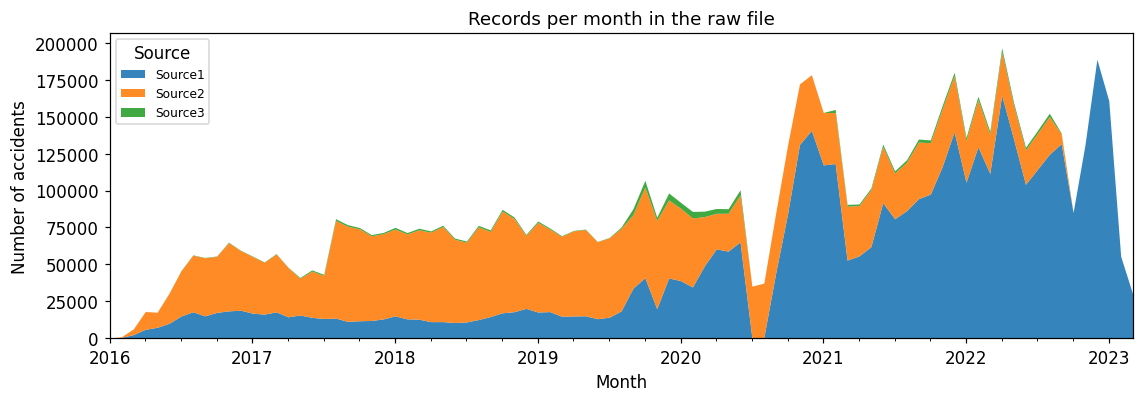

In [5]:
dup = raw["id"].duplicated().sum() if "id" in raw else raw.duplicated().sum()
print(f"rows: {len(raw):,} | duplicate records: {dup:,} | unparseable Start_Time: {raw.start_time.isna().sum():,}")
print("date range:", raw.start_time.min(), "->", raw.start_time.max())
audit = pd.DataFrame({"missing_%": raw.isna().mean().mul(100).round(2), "dtype": raw.dtypes.astype(str)})
display(audit)

per = raw.start_time.dt.to_period("M")
fig, ax = plt.subplots(figsize=(12, 3.6))
if "source" in raw:
    ct = raw.groupby([per, "source"]).size().unstack(fill_value=0)
    ct.index = ct.index.to_timestamp()
    ct.plot.area(ax=ax, linewidth=0, alpha=0.9)
    ax.legend(title="Source", fontsize=8)
else:
    m = raw.groupby(per).size(); m.index = m.index.to_timestamp()
    ax.fill_between(m.index, m.values, step="mid", alpha=0.8)
ax.set_title("Records per month in the raw file")
ax.set_xlabel("Month"); ax.set_ylabel("Number of accidents")
save(fig, "fig_audit_rows_per_month")

## 2. Cleaning (follows A1)
Duplicate removal, severity range check, state/city normalisation, weather-condition grouping, plausibility limits for numeric fields, then the A1 weather fill (station code by city then state; missing readings from the nearest-in-time reading of the same station).

In [6]:
df = raw
del raw
n0 = len(df)
df = df.drop_duplicates("id") if "id" in df else df.drop_duplicates()
n_dup = n0 - len(df)

df["severity"] = pd.to_numeric(df["severity"], errors="coerce")
df = df.dropna(subset=["start_time", "state", "severity"])
df = df[df["severity"].between(1, 4)].copy()
df["severity"] = df["severity"].astype(int)
df["state"] = df["state"].astype(str).str.strip().str.upper()
if "city" in df:
    df["city"] = df["city"].astype("string").str.strip().str.upper()

t = df["start_time"]
df["date"] = t.dt.normalize()
df["year"] = t.dt.year
df["month"] = t.dt.month
df["month_start"] = t.dt.to_period("M").dt.to_timestamp()
df["dow"] = t.dt.dayofweek                       # 0 = Monday
df["doy"] = t.dt.dayofyear
df["hour_f"] = t.dt.hour + t.dt.minute / 60      # continuous hour of day

# ---- weather grouping (map the few thousand unique strings once, not millions of rows) ----
def weather_group(w):
    s = str(w).lower()
    if "thunder" in s or "t-storm" in s:                                         return "Thunderstorm"
    if any(k in s for k in ("snow", "sleet", "wintry", "ice pellets", "hail")):  return "Snow"
    if any(k in s for k in ("rain", "drizzle", "shower")):                       return "Rain"
    if any(k in s for k in ("fog", "mist", "haze", "smoke")):                    return "Fog"
    if any(k in s for k in ("cloud", "overcast")):                               return "Cloudy"
    if any(k in s for k in ("clear", "fair", "sunny")):                          return "Clear"
    if s in ("unknown", "nan", "", "<na>"):                                      return "Unknown"
    return "Other"

if "weather" in df:
    mapping = {w: weather_group(w) for w in df["weather"].dropna().unique()}
    df["weather_group"] = df["weather"].map(mapping).fillna("Unknown")



# ---- numeric cleaning: impossible values -> NaN ----
LIMITS = {"temp": (-40, 130), "humidity": (0, 100), "visibility": (0, 20),
          "wind": (0, 120), "precip": (0, 10), "distance": (0, 50)}
for c, (lo, hi) in LIMITS.items():
    if c in df:
        x = pd.to_numeric(df[c], errors="coerce")
        df[c] = x.where(x.between(lo, hi))

# ---- A1 weather-fill pipeline ----
wcols = [c for c in ("temp", "humidity", "visibility", "wind", "precip") if c in df]
can_fill = FILL_WEATHER and wcols and "airport" in df

def fill_station_codes(d):
    """UNKNOWN / missing station -> most frequent station of the same city, then of the same state (as in A1)."""
    ap = d["airport"].astype("object").replace({"UNKNOWN": np.nan, "": np.nan, "nan": np.nan})
    known = d.assign(airport=ap).dropna(subset=["airport"])
    state_mode = known.groupby("state")["airport"].agg(lambda s: s.value_counts().idxmax())
    if "city" in d:
        city_mode = (known.groupby(["state", "city"]).airport.agg(lambda s: s.value_counts().idxmax()))
        key = pd.MultiIndex.from_frame(d[["state", "city"]])
        ap = ap.fillna(pd.Series(city_mode.reindex(key).values, index=d.index))
    return ap.fillna(d["state"].map(state_mode))


def nearest_station_fill(d, col, max_gap=None):
    """Fill NaN in `col` with the nearest-in-time non-null reading from the same station (merge_asof by station)."""
    miss = d[col].isna() & d["airport"].notna()
    if not miss.any():
        return d[col]
    known = (d.loc[d[col].notna() & d["airport"].notna(), ["airport", "wtime", col]]
               .sort_values("wtime"))
    m = (d.loc[miss, ["airport", "wtime"]].rename_axis("_i").reset_index().sort_values("wtime"))
    res = pd.merge_asof(m, known, on="wtime", by="airport", direction="nearest", tolerance=max_gap)
    out = d[col].copy()
    out.loc[res["_i"].values] = res[col].values
    return out

if can_fill:
    before = df[wcols].isna().mean().mul(100).round(2)
    n_unknown = int(df["airport"].isin(["UNKNOWN", ""]).sum() + df["airport"].isna().sum())
    df["airport"] = fill_station_codes(df)
    if "wtime" not in df:
        df["wtime"] = df["start_time"]
    n_wt = int(df["wtime"].isna().sum())
    df["wtime"] = df["wtime"].fillna(df["start_time"])          # proxy: accident start time
    for c in wcols:
        df[c] = nearest_station_fill(df, c, MAX_GAP)
    after = df[wcols].isna().mean().mul(100).round(2)
    print(f"station codes missing/UNKNOWN before fill: {n_unknown:,} | still missing: {int(df['airport'].isna().sum()):,}")
    print(f"Weather_Timestamp recovered from Start_Time: {n_wt:,}")
    display(pd.DataFrame({"missing % before": before, "missing % after": after}))
else:
    print("weather fill skipped (FILL_WEATHER off, or Airport_Code column not found)")

# ---- analysis range ----
dfr = df[(df["start_time"] >= RANGE_START) & (df["start_time"] < pd.Timestamp(RANGE_END) + pd.Timedelta(days=1))].copy()
print(f"\nduplicates removed: {n_dup:,} | rows kept: {len(df):,} | rows in analysis range: {len(dfr):,}")
print(dfr.groupby("year").size().rename("accidents per year").to_frame().T)





station codes missing/UNKNOWN before fill: 22,635 | still missing: 0
Weather_Timestamp recovered from Start_Time: 120,228


,missing % before,missing % after
temp,2.12,0.18
humidity,2.25,0.18
visibility,2.42,0.20
wind,7.39,0.46
precip,28.51,2.13



duplicates removed: 0 | rows kept: 7,728,394 | rows in analysis range: 7,070,940
year                  2017    2018    2019     2020     2021     2022
accidents per year  718093  893426  954303  1178913  1563753  1762452


### Outliers
IQR fences (3 x IQR) are reported for information. Wind, precipitation and distance are capped at the 99.9th percentile (winsorised).

In [7]:
num_cols = [c for c in ("temp", "humidity", "visibility", "wind", "precip", "distance") if c in dfr]
rows = {}
for c in num_cols:
    x = dfr[c].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 3 * iqr, q3 + 3 * iqr
    n_out = int(((x < lo) | (x > hi)).sum())
    rows[c] = dict(Q1=q1, Q3=q3, lower_fence=lo, upper_fence=hi, flagged=n_out,
                   flagged_pct=100 * n_out / len(x), p99_9=x.quantile(0.999), max=x.max())
outlier_report = pd.DataFrame(rows).T.round(2)
display(outlier_report)

# Winsorising caps extreme values but piles them up AT the cap; this shows as a small bump at 31 mph in Ridgeline C.
WINSORISE = [c for c in ("wind", "precip", "distance") if c in dfr and (c != "wind" or WINSORISE_WIND)]          # heavy right tail
for c in WINSORISE:
    cap = dfr[c].quantile(0.999)
    n_cap = int((dfr[c] > cap).sum())
    dfr[c] = dfr[c].clip(upper=cap)
    print(f"{c}: {n_cap:,} values capped at the 99.9th percentile ({cap:.2f})")

,Q1,Q3,lower_fence,upper_fence,flagged,flagged_pct,p99_9,max
temp,50.0,76.00,-28.0,154.00,275.0,0.00,105.80,129.20
humidity,48.0,84.00,-60.0,192.00,0.0,0.00,100.00,100.00
visibility,10.0,10.00,10.0,10.00,1387495.0,19.66,15.00,20.00
wind,4.6,10.00,-11.6,26.20,22616.0,0.32,31.00,119.70
precip,0.0,0.00,0.0,0.00,1249169.0,18.04,0.91,10.00
distance,0.0,0.47,-1.4,1.86,562132.0,7.95,19.45,49.98


wind: 6,761 values capped at the 99.9th percentile (31.00)
precip: 6,894 values capped at the 99.9th percentile (0.91)
distance: 7,071 values capped at the 99.9th percentile (19.45)


### Validation
Assertions on ranges and uniqueness, then a data-quality table of the analysis table (2017-2022).

In [8]:
# --- validation checks ---
assert dfr["start_time"].notna().all() and dfr["state"].notna().all()
if "id" in dfr: assert dfr["id"].is_unique, "duplicate IDs remain"
assert dfr["severity"].between(1, 4).all()
if "humidity" in dfr:   assert dfr["humidity"].dropna().between(0, 100).all()
if "visibility" in dfr: assert (dfr["visibility"].dropna() >= 0).all()
if "wind" in dfr:       assert (dfr["wind"].dropna() >= 0).all()
print("all validation checks passed")

# --- data-quality report of the analysis table ---
q_cols = [c for c in ("severity", "temp", "humidity", "visibility", "wind", "precip", "distance") if c in dfr]
quality = pd.DataFrame({"missing %": dfr[q_cols].isna().mean().mul(100),
                        "min": dfr[q_cols].min(), "median": dfr[q_cols].median(), "max": dfr[q_cols].max()}).round(2)
display(quality)
print("rows in analysis table:", f"{len(dfr):,}", "| states:", dfr["state"].nunique(),
      "| period:", dfr["start_time"].min().date(), "to", dfr["start_time"].max().date())

all validation checks passed


,missing %,min,median,max
severity,0.00,1.0,2.00,4.00
temp,0.17,-40.0,64.00,129.20
humidity,0.17,1.0,67.00,100.00
visibility,0.19,0.0,10.00,20.00
wind,0.45,0.0,7.00,31.00
precip,2.06,0.0,0.00,0.91
distance,0.01,0.0,0.03,19.45


rows in analysis table: 7,070,940 | states: 49 | period: 2017-01-01 to 2022-12-31


## 3. Aggregation
Monthly counts per top-10 state and per weather group, weekly counts per severity (for one year), and derived columns (season, day type, part of day).

In [9]:
full_months = pd.date_range(RANGE_START, RANGE_END, freq="MS")
top_states = dfr["state"].value_counts().head(TOP_N).index.tolist()

# monthly accidents per top state, full range
monthly_state = (dfr[dfr["state"].isin(top_states)]
                 .groupby(["month_start", "state"]).size().unstack(fill_value=0)
                 .reindex(full_months, fill_value=0)[top_states])

# (monthly_sevmean is computed for reference but not plotted in the final figures)
# monthly MEAN severity per top state (a different measure than counts)
monthly_sevmean = (dfr[dfr["state"].isin(top_states)]
                   .groupby(["month_start", "state"])["severity"].mean().unstack()
                   .reindex(full_months)[top_states].interpolate(limit_direction="both"))

# weekly accidents per severity inside one focus year (finer time resolution, different group)
assert pd.Timestamp(f"{FOCUS_YEAR}-01-01") >= pd.Timestamp(RANGE_START) and pd.Timestamp(f"{FOCUS_YEAR}-12-31") <= pd.Timestamp(RANGE_END), "FOCUS_YEAR must be inside the range"
days_fy = pd.date_range(f"{FOCUS_YEAR}-01-01", f"{FOCUS_YEAR}-12-31", freq="D")
daily_sev = (dfr[dfr["year"] == FOCUS_YEAR].groupby(["date", "severity"]).size().unstack(fill_value=0)
             .reindex(days_fy, fill_value=0))
daily_sev.columns = [f"Severity {c}" for c in daily_sev.columns]
weekly_sev = daily_sev.resample("W").sum().iloc[1:-1]       # drop the partial first/last week

# monthly accidents per weather group, full range
if "weather_group" in dfr:
    monthly_weather = (dfr.groupby(["month_start", "weather_group"]).size().unstack(fill_value=0)
                       .reindex(full_months, fill_value=0))
    monthly_weather = monthly_weather.loc[:, monthly_weather.sum() > 0.005 * monthly_weather.values.sum()]
    monthly_weather = monthly_weather[monthly_weather.sum().sort_values(ascending=False).index]

if DROP_UNKNOWN_WEATHER and "weather_group" in dfr:
    monthly_weather = monthly_weather.drop(columns="Unknown", errors="ignore")
print("top states:", top_states)
print("monthly_state", monthly_state.shape, "| weekly_sev", weekly_sev.shape,
      "| monthly_weather", monthly_weather.shape if "weather_group" in dfr else "n/a")
monthly_state.head()# Derived columns (on the analysis table)
SEASON = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
          6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
dfr["season"] = dfr["month"].map(SEASON)
dfr["day_type"] = np.where(dfr["dow"] >= 5, "Weekend", "Weekday")
hour = dfr["start_time"].dt.hour
dfr["part_of_day"] = pd.cut(hour, [-1, 5, 11, 16, 20, 23], labels=["Night", "Morning", "Afternoon", "Evening", "Late night"])
dfr["rush_hour"] = (dfr["day_type"] == "Weekday") & hour.isin([7, 8, 16, 17, 18])
if "temp" in dfr:
    dfr["temp_c"] = ((dfr["temp"] - 32) * 5 / 9).round(1)

# quick check of the new columns: share of accidents and mean severity per group
check = pd.concat({c: dfr.groupby(c, observed=True).agg(accidents=("severity", "size"), mean_severity=("severity", "mean"))
                   for c in ("season", "day_type", "part_of_day", "rush_hour")})
check["share %"] = (100 * check["accidents"] / len(dfr)).round(1)
display(check.round(3))

top states: ['CA', 'FL', 'TX', 'SC', 'NC', 'NY', 'VA', 'PA', 'MN', 'OR']
monthly_state (72, 10) | weekly_sev (51, 4) | monthly_weather (72, 7)


accidents  mean_severity  share %
season      Autumn        1911269          2.192     27.0
            Spring        1627856          2.221     23.0
            Summer        1550599          2.228     21.9
            Winter        1981216          2.198     28.0
day_type    Weekday       5930489          2.201     83.9
            Weekend       1140451          2.246     16.1
part_of_day Night          719316          2.207     10.2
            Morning       2401955          2.202     34.0
            Afternoon     2116274          2.204     29.9
            Evening       1387838          2.222     19.6
            Late night     445557          2.223      6.3
rush_hour   False         4800748          2.215     67.9
            True          2270192          2.194     32.1

## 4. Horizon plots
`horizon_matrix` draws one horizon row per series. Each variant changes **one** setting: number of bands, normalisation (`raw`, `index` = value / median, `detrend` = value / 12-month average), baseline, scaling (shared or per series) or row order.

In [10]:
POS_CMAP, NEG_CMAP = "Reds", "Blues"

def order_series(d, how="total"):
    cols = list(d.columns)
    if how == "total":
        return list(d.sum().sort_values(ascending=False).index)
    if how == "peak":                                  # earliest peak first
        return list(d.idxmax().sort_values().index)
    if how == "similarity":                            # series that move together sit next to each other
        z = ((d - d.mean()) / d.std().replace(0, 1)).fillna(0)
        return [cols[i] for i in leaves_list(linkage(z.T.values, method="average", metric="correlation"))]
    return cols

# One horizon row: the deviation from the baseline is split into n_bands layers of equal height h.
# Positive deviations use red shades, negative use blue; darker shade = larger deviation. Rows share the band height
# when scaling='shared', so colour intensity is comparable across rows. step='mid' centres each bar on its timestamp.
def _horizon(ax, x, y, n_bands, baseline, vmax, step=False):
    dev = np.asarray(y, float) - baseline
    if step and STEP_POST:                               # extend the last bar by one period so it has full width
        x = pd.DatetimeIndex(x); x = x.append(x[-1:] + (x[-1] - x[-2])); dev = np.append(dev, dev[-1])
    h = vmax / n_bands
    shades = np.linspace(0.30, 0.95, n_bands)
    for part, cmap in ((np.clip(dev, 0, None), POS_CMAP), (np.clip(-dev, 0, None), NEG_CMAP)):
        for k in range(n_bands):
            layer = np.clip(part - k * h, 0, h)
            if layer.any():
                ax.fill_between(x, 0, layer, step=("post" if STEP_POST else "mid") if step else None,
                                color=plt.get_cmap(cmap)(shades[k]), linewidth=0)
    ax.set_ylim(0, h)
    ax.set_yticks([])
    return h

def horizon_matrix(d, variants, figsize, suptitle, fname, step=False, unit="accidents", xfmt=None, xlabel="Date"):
    """d: DataFrame (time x series). variants: list of dicts with keys
    title, n_bands, baseline ('zero'|'median'), scaling ('shared'|'per_series'),
    transform ('raw' | 'index' = value / series median | 'detrend' = value / rolling average, removes long-term growth), order ('total'|'peak'|'similarity'|'given')."""
    nrow, ncol = d.shape[1], len(variants)
    fig, axes = plt.subplots(nrow, ncol, figsize=figsize, sharex=True, squeeze=False, constrained_layout=True)
    for j, v in enumerate(variants):
        v = {**dict(n_bands=3, baseline="median", scaling="shared", transform="raw", order="total"), **v}
        dd = d[order_series(d, v["order"])]
        if v["transform"] == "index":                         # value / series median
            dd = dd / dd.median().replace(0, np.nan)
        # detrend: divide by the centred 12-month moving average. At the first/last ~6 months the window is truncated
        # (min_periods), so edge values are less reliable.
        elif v["transform"] == "detrend":                     # value / its own rolling average (removes growth)
            w = v.get("window", 12)
            dd = dd / dd.rolling(w, center=True, min_periods=(w if STRICT_DETREND else max(2, w // 2))).mean().replace(0, np.nan)
        base = dd.median() if v["baseline"] == "median" else pd.Series(0.0, index=dd.columns)
        dev = (dd - base).abs().max()
        for i, col in enumerate(dd.columns):
            ax = axes[i, j]
            vmax = dev.max() if v["scaling"] == "shared" else dev[col]
            h = _horizon(ax, dd.index, dd[col].values, v["n_bands"], base[col], max(float(vmax), 1e-9), step)
            for s in ("top", "right", "left"):
                ax.spines[s].set_visible(False)
            ax.spines["bottom"].set_visible(i == nrow - 1)
            ax.axhline(0, color="0.85", lw=0.5)
            ax.set_ylabel(col, rotation=0, ha="right", va="center", fontsize=8)
            ax.text(1.005, 0.5, f"{h:,.0f}" if (v["transform"] == "raw" and unit == "accidents") else f"{h:,.3f}",
                    transform=ax.transAxes, fontsize=6, va="center", color="0.4")
        axes[0, j].set_title(v.get("title", ""), fontsize=9)
        if xfmt:                                           # e.g. "%b" to show month names
            axes[-1, j].xaxis.set_major_locator(mdates.MonthLocator())
            axes[-1, j].xaxis.set_major_formatter(mdates.DateFormatter(xfmt))
        else:
            loc = mdates.AutoDateLocator()
            axes[-1, j].xaxis.set_major_locator(loc)
            axes[-1, j].xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
        axes[-1, j].set_xlabel(xlabel)
    fig.suptitle(suptitle)
    fig.text(0.5, -0.02, "Red = above baseline, blue = below baseline, darker = larger deviation. "
             "The small number at the right of each row is the size of one band "
             f"({'ratio to the series level' if variants[0].get('transform', 'raw') != 'raw' else unit}).",
             ha="center", fontsize=8, color="0.3")
    save(fig, fname)

def series_stats(d):
    """Descriptive statistics of each time series (one row per group)."""
    return pd.DataFrame({"total": d.sum(), "mean per period": d.mean().round(2), "std": d.std().round(2),
                         "CV (std/mean)": (d.std() / d.mean()).round(2),
                         "peak period": d.idxmax().dt.strftime("%Y-%m-%d")}).sort_values("total", ascending=False)

### H1. Number of bands (2, 4, 6)
Same four states, detrended. More bands compress the same range into a shorter row but make small deviations visible.

saved images/fig_h1_bands.png


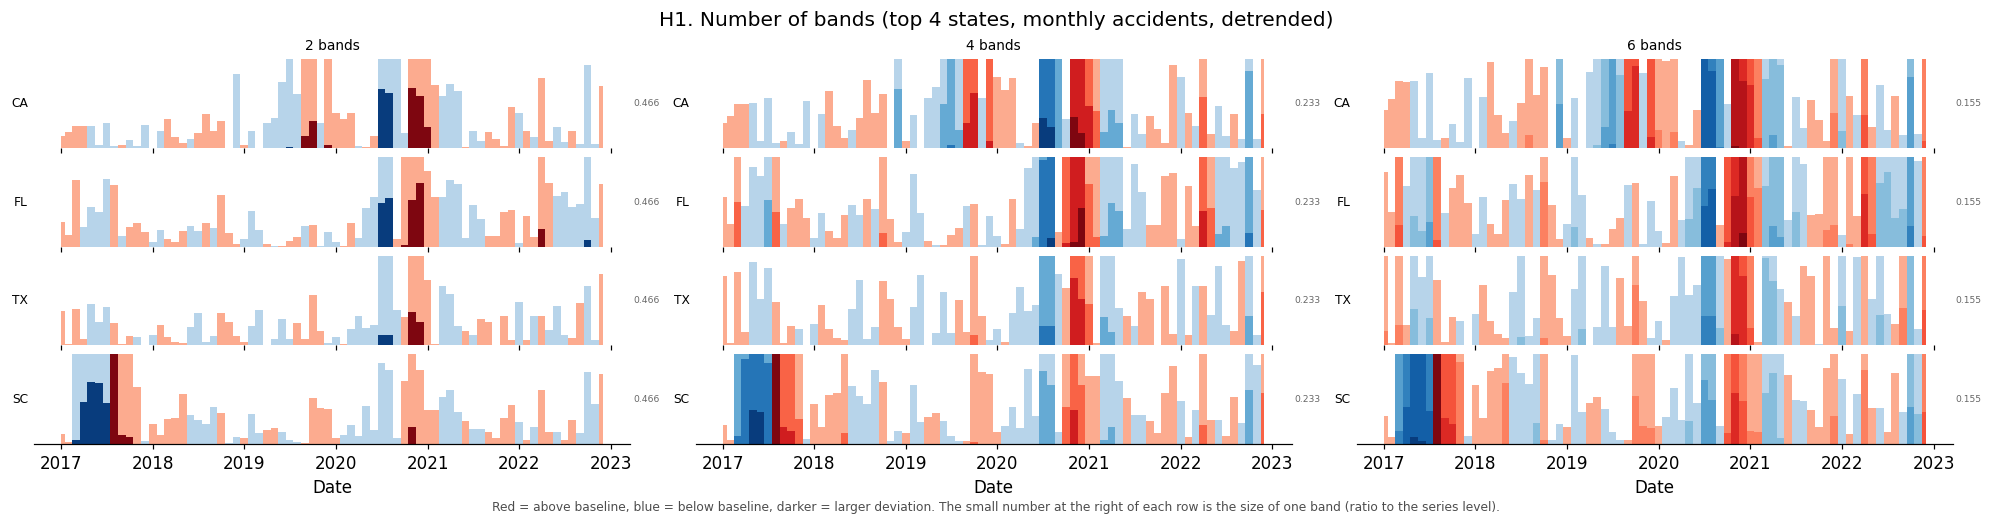

,total,mean per period,std,CV (std/mean),peak period
state,,,,,
CA,1526422,21200.31,10241.02,0.48,2022-04-01
FL,820889,11401.24,8950.65,0.79,2022-04-01
TX,519244,7211.72,1662.98,0.23,2020-12-01
SC,371008,5152.89,2110.98,0.41,2022-04-01


In [11]:
four = monthly_state[order_series(monthly_state, "total")[:4]]
horizon_matrix(four, [dict(title=f"{n} bands", n_bands=n, transform="detrend", scaling="shared") for n in (2, 4, 6)],
               figsize=(18, 4.5), suptitle="H1. Number of bands (top 4 states, monthly accidents, detrended)",
               fname="fig_h1_bands", step=True)
display(series_stats(four))

### H3. Normalisation (raw, relative index, detrended)
Raw counts are dominated by the largest series and by long-term growth; `index` shows growth relative to each state's median; `detrend` isolates month-to-month variation.

saved images/fig_h3_transform.png


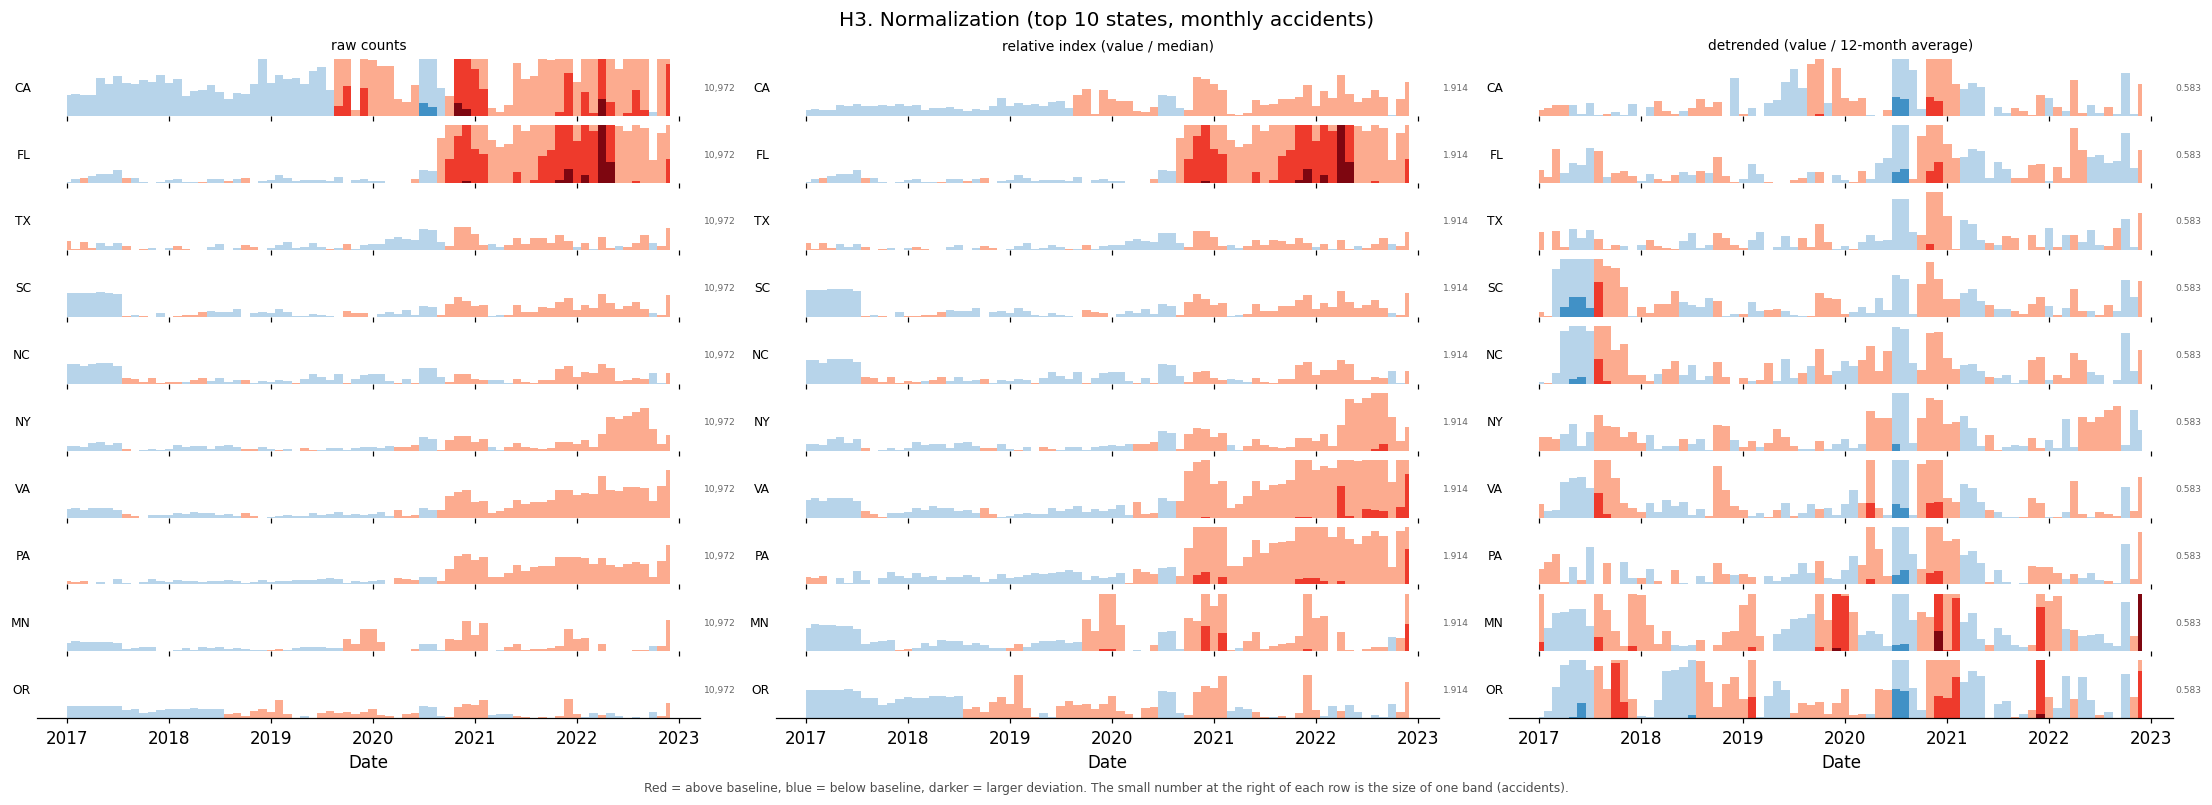

In [12]:
horizon_matrix(monthly_state, [dict(title="raw counts", transform="raw", scaling="shared"),
                               dict(title="relative index (value / median)", transform="index", scaling="shared"),
                               dict(title="detrended (value / 12-month average)", transform="detrend", scaling="shared")],
               figsize=(20, 7), suptitle=f"H3. Normalization (top {TOP_N} states, monthly accidents)",
               fname="fig_h3_transform", step=True)

### H4. Row order (total, peak month, similarity)
Similarity ordering uses hierarchical clustering on correlations so that states with similar profiles are adjacent.

saved images/fig_h4_order.png


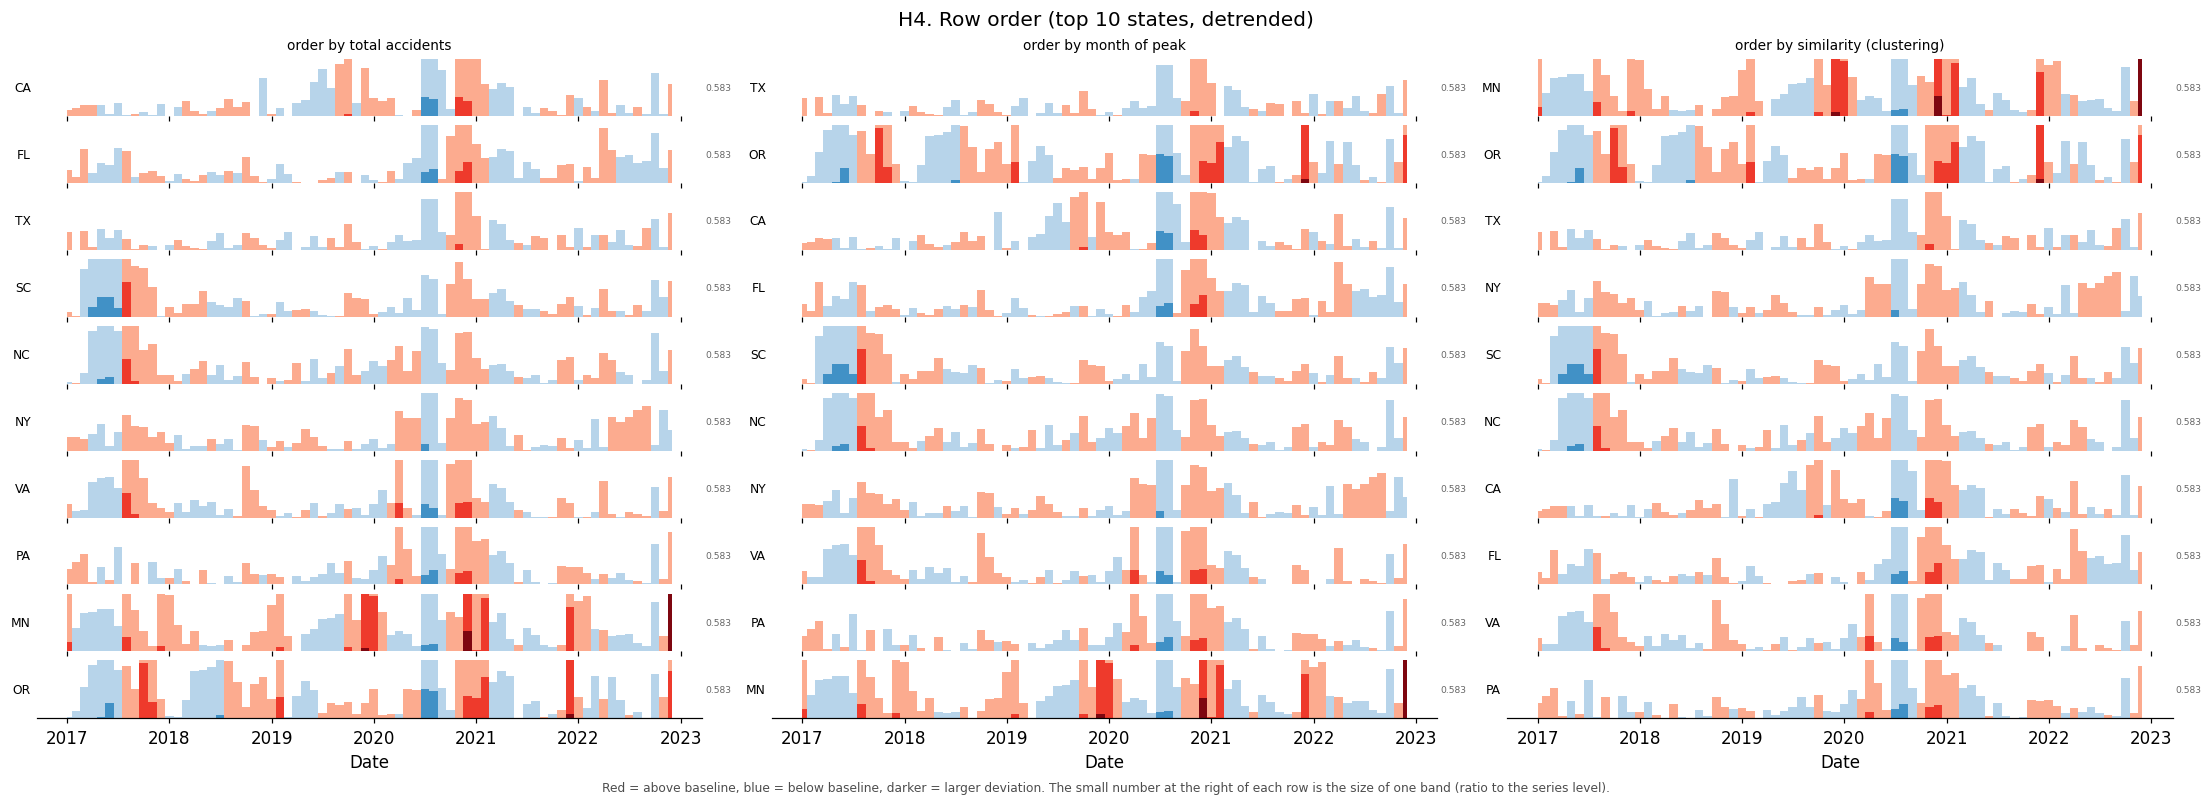

order by similarity: ['MN', 'OR', 'TX', 'NY', 'SC', 'NC', 'CA', 'FL', 'VA', 'PA']
mean correlation of each state with the others:


,mean corr
state,
VA,0.68
FL,0.65
NC,0.65
TX,0.64
PA,0.63
SC,0.60
OR,0.58
CA,0.57
MN,0.53


In [13]:
horizon_matrix(monthly_state, [dict(title="order by total accidents", order="total", transform="detrend"),
                               dict(title="order by month of peak", order="peak", transform="detrend"),
                               dict(title="order by similarity (clustering)", order="similarity", transform="detrend")],
               figsize=(20, 7), suptitle=f"H4. Row order (top {TOP_N} states, detrended)", fname="fig_h4_order", step=True)

# how similar are the states? correlation of the detrended monthly series
detr = monthly_state / monthly_state.rolling(12, center=True, min_periods=(12 if STRICT_DETREND else 6)).mean()
corr = detr.corr().round(2)
print("order by similarity:", order_series(monthly_state, "similarity"))
print("mean correlation of each state with the others:")
display((corr.sum() - 1).div(len(corr) - 1).round(2).sort_values(ascending=False).to_frame("mean corr"))

### Final horizon plots
Settings: 4 bands, median baseline, shared scale, detrended, similarity order.

In [14]:
HFINAL = dict(n_bands=4, baseline="median", scaling="shared", transform="detrend", order="similarity") 

**Horizon A:** monthly accidents, top-10 states.

saved images/fig_horizon_A_states_monthly.png


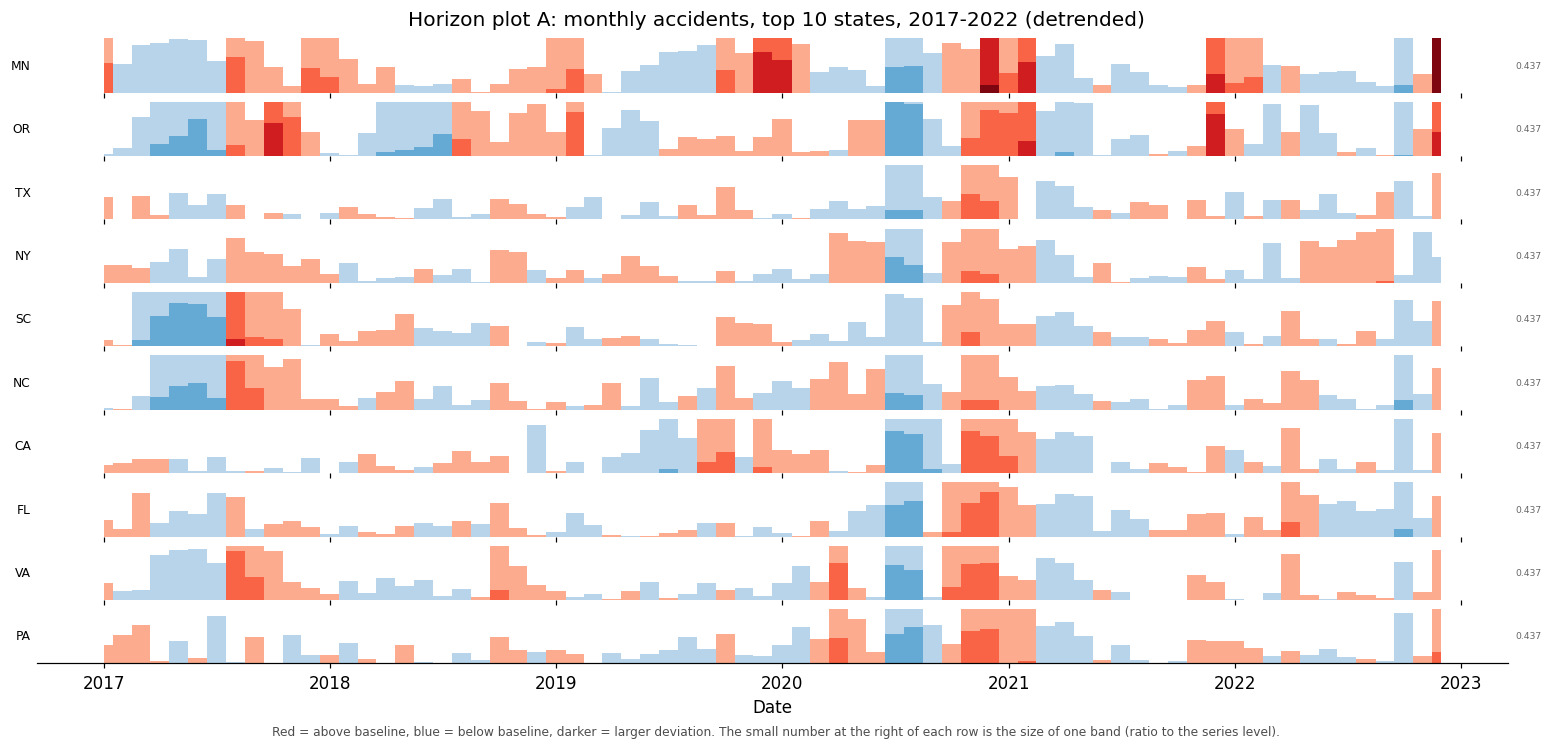

,total,mean per period,std,CV (std/mean),peak period
state,,,,,
CA,1526422,21200.31,10241.02,0.48,2022-04-01
FL,820889,11401.24,8950.65,0.79,2022-04-01
TX,519244,7211.72,1662.98,0.23,2020-12-01
SC,371008,5152.89,2110.98,0.41,2022-04-01
NC,322919,4484.99,1752.47,0.39,2022-04-01
NY,317043,4403.38,2129.98,0.48,2022-09-01
VA,285382,3963.64,2706.50,0.68,2022-12-01
PA,264783,3677.54,2375.81,0.65,2022-12-01
MN,180568,2507.89,1777.91,0.71,2022-12-01


In [15]:
horizon_matrix(monthly_state, [dict(title="", **HFINAL)], figsize=(14, 6.5),
               suptitle=f"Horizon plot A: monthly accidents, top {TOP_N} states, {RANGE_START[:4]}-{RANGE_END[:4]} (detrended)",
               fname="fig_horizon_A_states_monthly", step=True)
display(series_stats(monthly_state))

**Horizon B:** monthly accidents by weather group (different grouping, same granularity). `Unknown` = missing `Weather_Condition`.

saved images/fig_horizon_B_weather_monthly.png


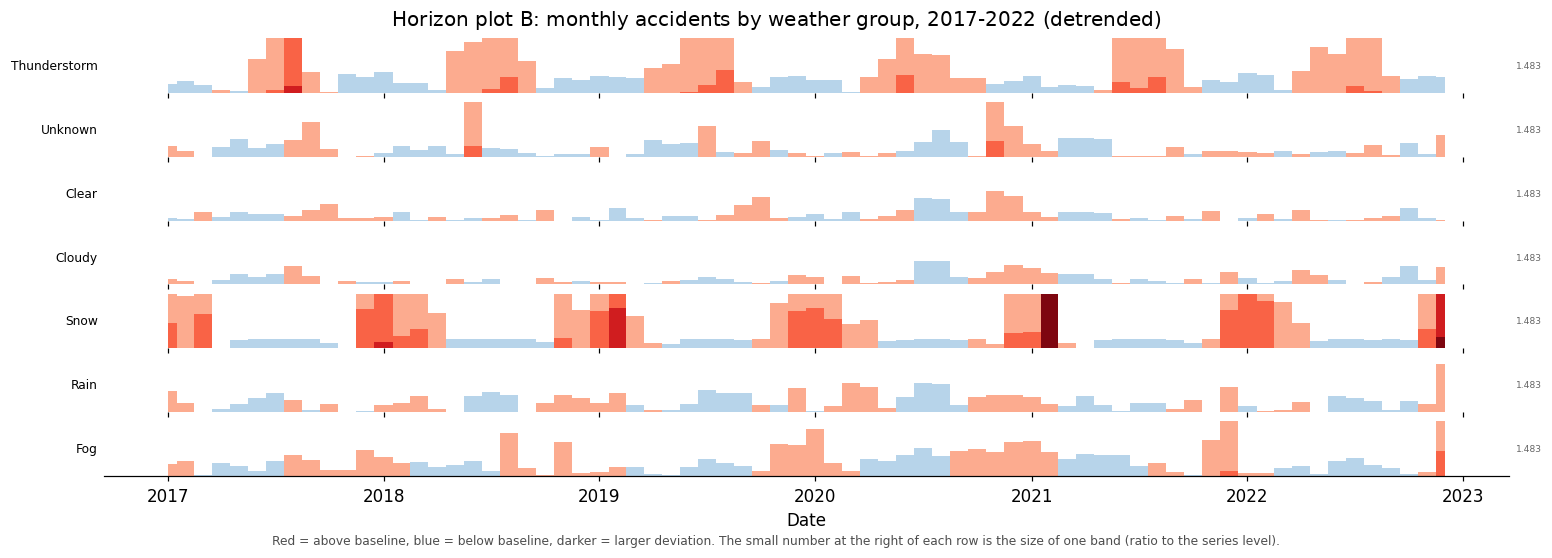

,total,mean per period,std,CV (std/mean),peak period
weather_group,,,,,
Clear,3129442,43464.47,22907.93,0.53,2022-04-01
Cloudy,2879939,39999.15,12382.03,0.31,2022-04-01
Rain,472908,6568.17,3164.19,0.48,2022-12-01
Fog,188142,2613.08,2106.18,0.81,2021-12-01
Unknown,158273,2198.24,1246.16,0.57,2020-11-01
Snow,153538,2132.47,3426.92,1.61,2021-02-01
Thunderstorm,84945,1179.79,1423.66,1.21,2022-08-01


In [16]:
horizon_matrix(monthly_weather, [dict(title="", **HFINAL)], figsize=(14, 4.8),
               suptitle=f"Horizon plot B: monthly accidents by weather group, {RANGE_START[:4]}-{RANGE_END[:4]} (detrended)",
               fname="fig_horizon_B_weather_monthly", step=True)
display(series_stats(monthly_weather))

**Horizon C:** yearly accidents, top-20 states (coarser granularity: year instead of month).

saved images/fig_horizon_C_states_yearly.png


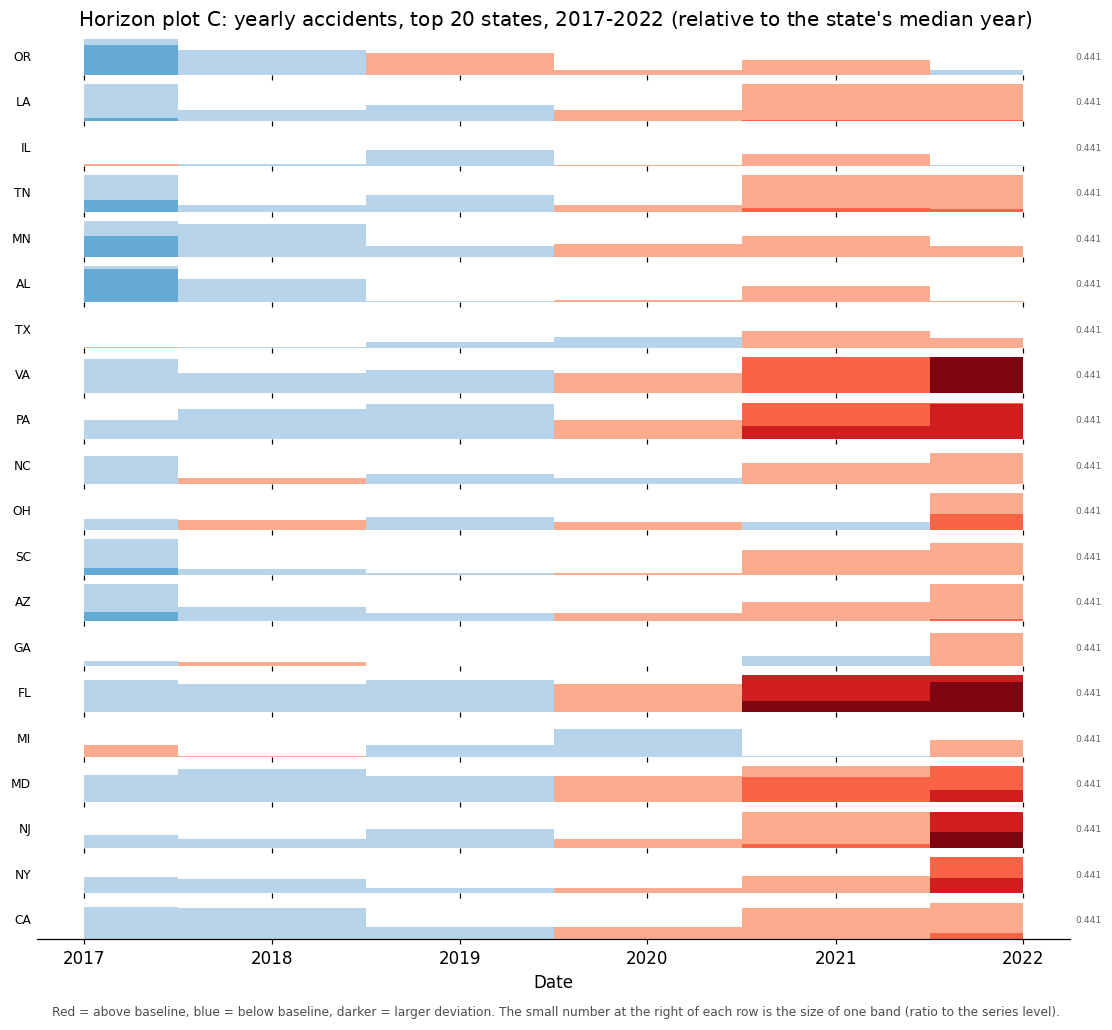

,total,mean per period,std,CV (std/mean),peak period
state,,,,,
CA,1526422,254403.67,94765.95,0.37,2022-01-01
FL,820889,136814.83,93229.07,0.68,2022-01-01
TX,519244,86540.67,10512.58,0.12,2021-01-01
SC,371008,61834.67,20049.08,0.32,2022-01-01
NC,322919,53819.83,13867.49,0.26,2022-01-01
NY,317043,52840.50,21672.44,0.41,2022-01-01
VA,285382,47563.67,30696.83,0.65,2022-01-01
PA,264783,44130.50,26276.99,0.60,2022-01-01
MN,180568,30094.67,12612.53,0.42,2021-01-01


In [17]:
top20 = dfr["state"].value_counts().head(20).index.tolist()
yearly_state = dfr[dfr["state"].isin(top20)].groupby(["year", "state"]).size().unstack(fill_value=0)[top20]
yearly_state.index = pd.to_datetime(yearly_state.index.astype(str) + "-01-01")      # one date per year; the bar is centred on the year tick
# relative index (value / the state's median year); rows ordered by the year of their peak
horizon_matrix(yearly_state, [dict(title="", n_bands=4, baseline="median", scaling="shared", transform="index", order="peak")],
               figsize=(10, 9), suptitle=f"Horizon plot C: yearly accidents, top 20 states, {RANGE_START[:4]}-{RANGE_END[:4]} (relative to the state's median year)",
               fname="fig_horizon_C_states_yearly", step=True)
display(series_stats(yearly_state))

**Horizon D:** month-of-year profile, one row per year (finer calendar structure, detrended).

saved images/fig_horizon_D_year_by_month.png


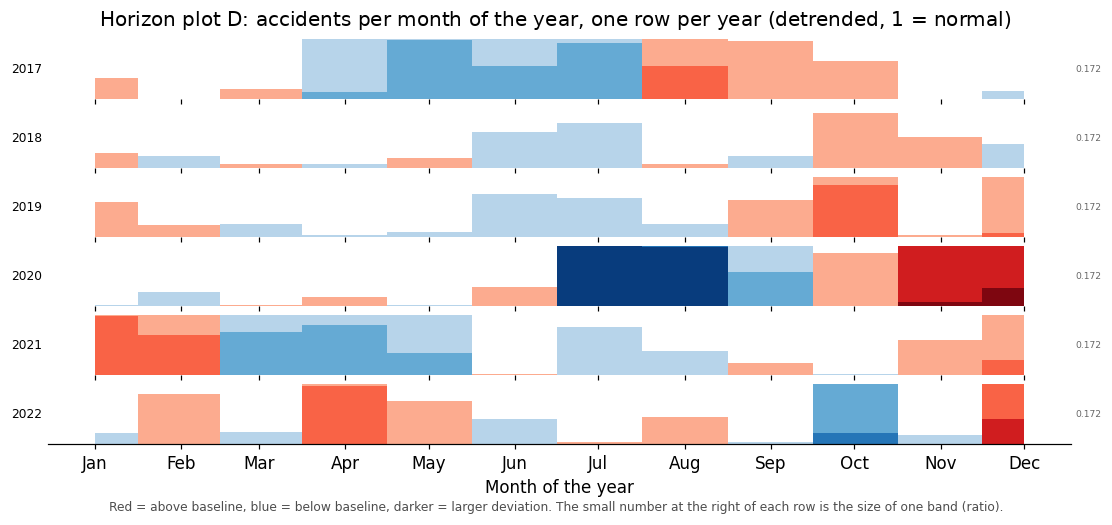

,min,max,std,peak month
2017,0.71,1.32,0.20,Aug
2018,0.88,1.17,0.08,Oct
2019,0.85,1.29,0.13,Oct
2020,0.36,1.61,0.38,Dec
2021,0.69,1.35,0.22,Jan
2022,0.58,1.37,0.20,Dec


In [18]:
# Fold the DETRENDED monthly series by year: rows = years, x-axis = month of the year.
# Dividing by the 12-month moving average first removes growth, so the rows differ only in their seasonal shape.
total = dfr.groupby("month_start").size().reindex(full_months, fill_value=0)
ratio = total / total.rolling(12, center=True, min_periods=(12 if STRICT_DETREND else 6)).mean()
fold = ratio.groupby([ratio.index.month, ratio.index.year]).first().unstack()           # month x year
fold.index = pd.to_datetime("2001-" + fold.index.astype(str) + "-01")                    # dummy year, only the month matters
fold.columns = fold.columns.astype(str)
horizon_matrix(fold, [dict(title="", n_bands=4, baseline="median", scaling="shared", transform="raw", order="given")],
               figsize=(10, 4.5), suptitle="Horizon plot D: accidents per month of the year, one row per year (detrended, 1 = normal)",
               fname="fig_horizon_D_year_by_month", step=True, unit="ratio", xfmt="%b", xlabel="Month of the year")
display(fold.agg(["min", "max", "std"]).round(2).T.join(fold.idxmax().dt.strftime("%b").rename("peak month")))

## 5. Ridgeline plots
Helpers: binned KDE, `ridgeline` (ridge per group; optional median/mean markers; `independent` scaling = each ridge scaled to its own peak, `shared` = common density scale) and `ridge_compare` for one-setting-at-a-time experiments.

In [21]:
DOW_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# Ridgelines use a fast binned Gaussian KDE (histogram + gaussian_filter1d). bw is in the units of x (hours, days, mph...).
# circular=True wraps the density around (hour of day, day of year). Each density integrates to 1.
def kde_binned(values, lo, hi, bw, nbins, circular=False):
    """Smoothed density from a fine histogram (fast for millions of rows). circular=True wraps around (hour, day of year)."""
    values = np.asarray(values, float)
    values = values[np.isfinite(values)]
    edges = np.linspace(lo, hi, nbins + 1)
    centers = (edges[:-1] + edges[1:]) / 2
    w = edges[1] - edges[0]
    counts, _ = np.histogram(values, bins=edges)
    sm = gaussian_filter1d(counts.astype(float), sigma=bw / w, mode="wrap" if circular else "constant")
    area = sm.sum() * w
    return centers, (sm / area if area > 0 else sm)

def ridgeline(ax, groups, lo, hi, bw, nbins, circular=False, overlap=1.5, order=None, scaling="independent",
              cmap="viridis", xlabel="", title=None, xticks=None, markers=False):
    """groups: dict name -> values. order: 'alpha'|'count'|'median'|'mean'|'peak'|None (given)|list of names (top to bottom)."""
    dens = {k: kde_binned(v, lo, hi, bw, nbins, circular) for k, v in groups.items()}
    stat = {"median": np.nanmedian, "mean": np.nanmean}
    if isinstance(order, str) and order in stat: names = sorted(groups, key=lambda k: stat[order](groups[k]))
    elif order == "peak": names = sorted(groups, key=lambda k: dens[k][0][np.argmax(dens[k][1])])
    elif order == "count":names = sorted(groups, key=lambda k: -len(groups[k]))
    elif order == "alpha":names = sorted(groups, key=str)
    elif order is None:   names = list(groups)
    else:                 names = list(order)
    gmax = max(d.max() for _, d in dens.values())
    colors = plt.get_cmap(cmap)(np.linspace(0.15, 0.9, len(names)))
    n = len(names)
    for i, k in enumerate(names):
        x, d = dens[k]
        y0 = n - 1 - i                                           # first name is drawn at the top
        h = d / (d.max() if scaling == "independent" else gmax) * overlap
        ax.fill_between(x, y0, y0 + h, color=colors[i], alpha=0.85, zorder=2 + i, linewidth=0)
        ax.plot(x, y0 + h, color="0.15", lw=0.8, zorder=2.5 + i)
        ax.axhline(y0, color="0.8", lw=0.5, zorder=1)
        if markers:                                              # median = vertical bar, mean = diamond
            v = np.asarray(groups[k], float); v = v[np.isfinite(v)]
            med, mean = np.median(v), v.mean()
            ax.plot([med, med], [y0, y0 + np.interp(med, x, h)], color="k", lw=1.6, zorder=3 + i)
            ax.plot(mean, y0, "D", color="white", mec="k", ms=4.5, zorder=10)
    ax.set_yticks(range(n))
    ax.set_yticklabels([f"{k}  (n={len(groups[k]):,})" for k in names][::-1])
    ax.set_xlim(lo, hi)
    ax.set_ylim(-0.1, n - 1 + overlap + 0.2)
    if xticks is not None:
        ax.set_xticks(xticks[0]); ax.set_xticklabels(xticks[1])
    ax.set_xlabel(xlabel + ("\n|  median     ◇  mean" if markers else ""))
    if title: ax.set_title(title)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    return names

def ridge_compare(groups, variants, figsize, suptitle, fname, **common):
    """One row of ridgeline panels; each variant changes only the setting under test."""
    fig, axes = plt.subplots(1, len(variants), figsize=figsize, constrained_layout=True, squeeze=False)
    for ax, v in zip(axes[0], variants):
        ridgeline(ax, groups, **{**common, **v})
    fig.suptitle(suptitle, fontsize=13)
    save(fig, fname)

def group_stats(groups):
    """n, mean, median, std and interquartile range per group."""
    rows = {}
    for k, v in groups.items():
        v = np.asarray(v, float); v = v[np.isfinite(v)]
        q1, q3 = np.percentile(v, [25, 75])
        rows[k] = dict(n=len(v), mean=v.mean(), median=np.median(v), std=v.std(), IQR=q3 - q1)
    return pd.DataFrame(rows).T.round(2)

def groups_by(frame, by, col, labels=None, keep=None):
    out = {}
    for k, g in frame.groupby(by)[col]:
        if keep is not None and k not in keep:
            continue
        out[labels[k] if labels else k] = g.values
    return out

HOUR_TICKS = (list(range(0, 25, 3)), [f"{h:02d}:00" for h in range(0, 25, 3)])
MONTH_TICKS = ([0, 31, 59, 90, 120, 151, 181, 212, 243, 273, 304, 334], MONTH_NAMES if "MONTH_NAMES" in globals() else
               ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
# settings shared by all plots of the same variable (keeps axis limits identical wherever plots are compared)
HOUR = dict(lo=0, hi=24, nbins=1440, circular=True, xlabel="Hour of day (local time)", xticks=HOUR_TICKS)
TEMP = dict(lo=-20, hi=115, nbins=540, xlabel="Temperature during the accident (°F)", markers=True)

### Group dictionaries
One entry per ridge: hour of day by weekday / state / severity, day of year by year, temperature by month / weather group, visibility and wind by severity. (State and temperature groups are prepared but not plotted in the final figures.)

In [22]:
# Group dictionaries used by the ridgeline plots (one entry per ridge)
SEV_LABELS = {k: f"Severity {k}" for k in range(1, 5)}
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

g_dow   = groups_by(dfr, "dow", "hour_f", labels=dict(enumerate(DOW_NAMES)))                 # hour of day per weekday
g_state = groups_by(dfr, "state", "hour_f", keep=set(top_states))                            # hour of day per top state
g_sev   = groups_by(dfr, "severity", "hour_f", labels=SEV_LABELS)                            # hour of day per severity
g_year  = groups_by(dfr, "year", "doy")                                                      # day of year per year
g_month = groups_by(dfr.dropna(subset=["temp"]), "month", "temp", labels=dict(zip(range(1, 13), MONTH_NAMES)))
g_w     = groups_by(dfr.dropna(subset=["temp"]), "weather_group", "temp")                    # temperature per weather group
g_w     = {k: v for k, v in g_w.items() if len(v) > 500 and k != "Unknown"}
g_vis   = groups_by(dfr.dropna(subset=["visibility"]), "severity", "visibility", labels=SEV_LABELS)
g_wind  = groups_by(dfr.dropna(subset=["wind"]), "severity", "wind", labels=SEV_LABELS)
print({"ridges": {"weekday": len(g_dow), "state": len(g_state), "month": len(g_month), "weather": len(g_w)}})

{'ridges': {'weekday': 7, 'state': 10, 'month': 12, 'weather': 7}}


### R-exp1. Bandwidth (0.2, 0.4, 0.8 h)
Small bandwidth keeps short peaks but adds noise; large bandwidth merges the morning and evening peaks.

saved images/fig_r1_bandwidth.png


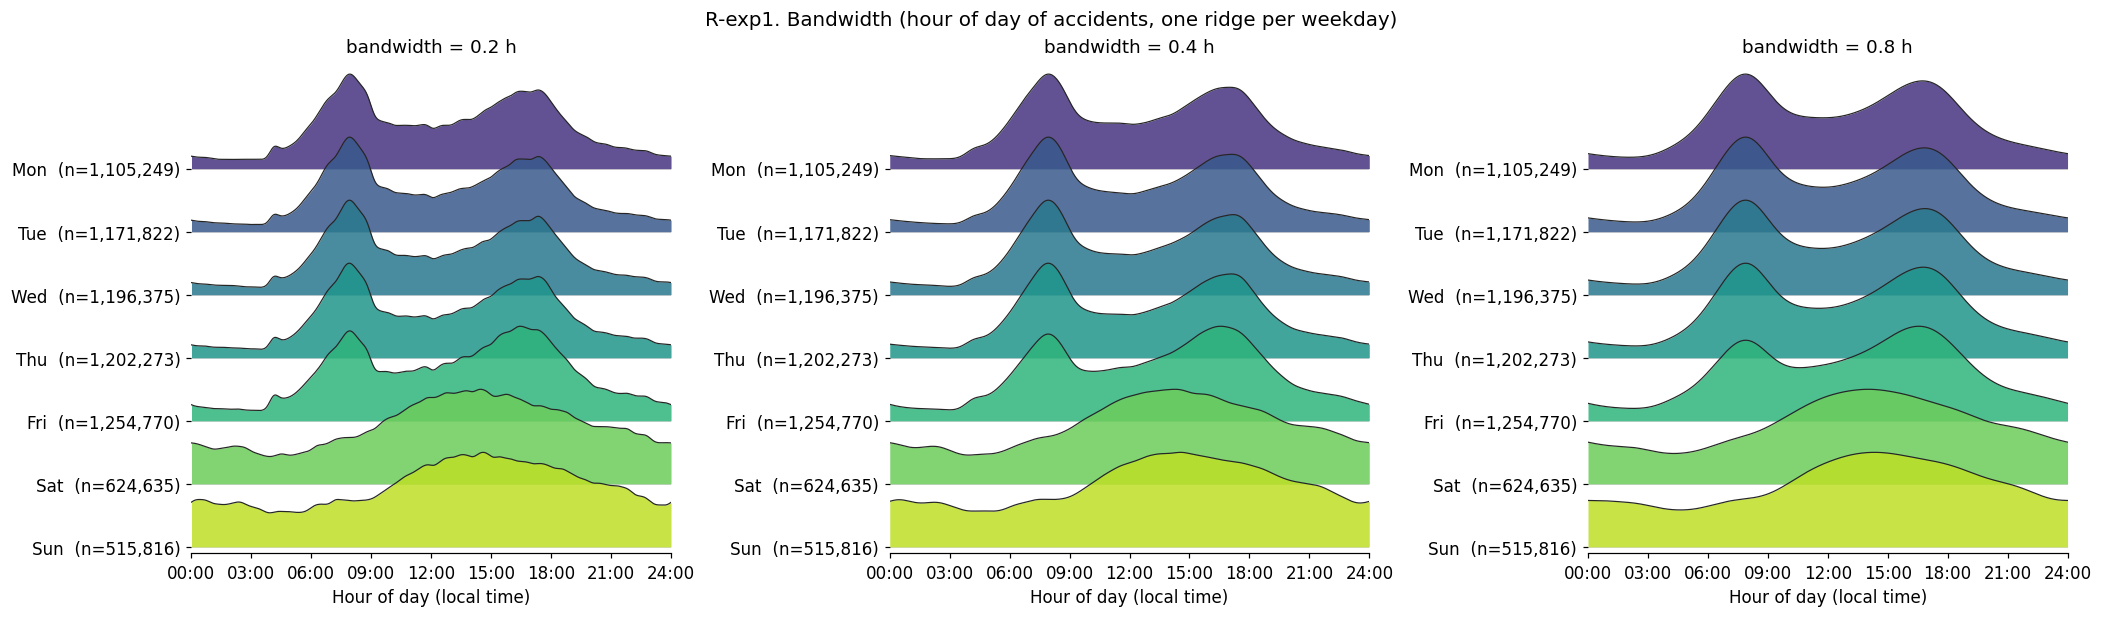

,n,mean,median,std,IQR
Mon,1105249.0,12.60,12.87,5.34,8.85
Tue,1171822.0,12.61,12.87,5.30,8.88
Wed,1196375.0,12.65,12.95,5.33,8.92
Thu,1202273.0,12.72,13.13,5.36,8.88
Fri,1254770.0,13.06,13.70,5.36,8.72
Sat,624635.0,13.24,13.73,6.02,8.45
Sun,515816.0,13.08,13.75,6.23,9.15


In [23]:
ridge_compare(g_dow, [dict(bw=b, title=f"bandwidth = {b} h") for b in (0.2, 0.4, 0.8)], figsize=(19, 5.5),
              suptitle="R-exp1. Bandwidth (hour of day of accidents, one ridge per weekday)", fname="fig_r1_bandwidth",
              order=DOW_NAMES, overlap=1.5, **HOUR)
display(group_stats(g_dow))

### R-exp4. Scaling (own peak vs common scale)
Own-peak scaling compares shapes; common scale also shows how many accidents each group has.

saved images/fig_r4_scaling.png


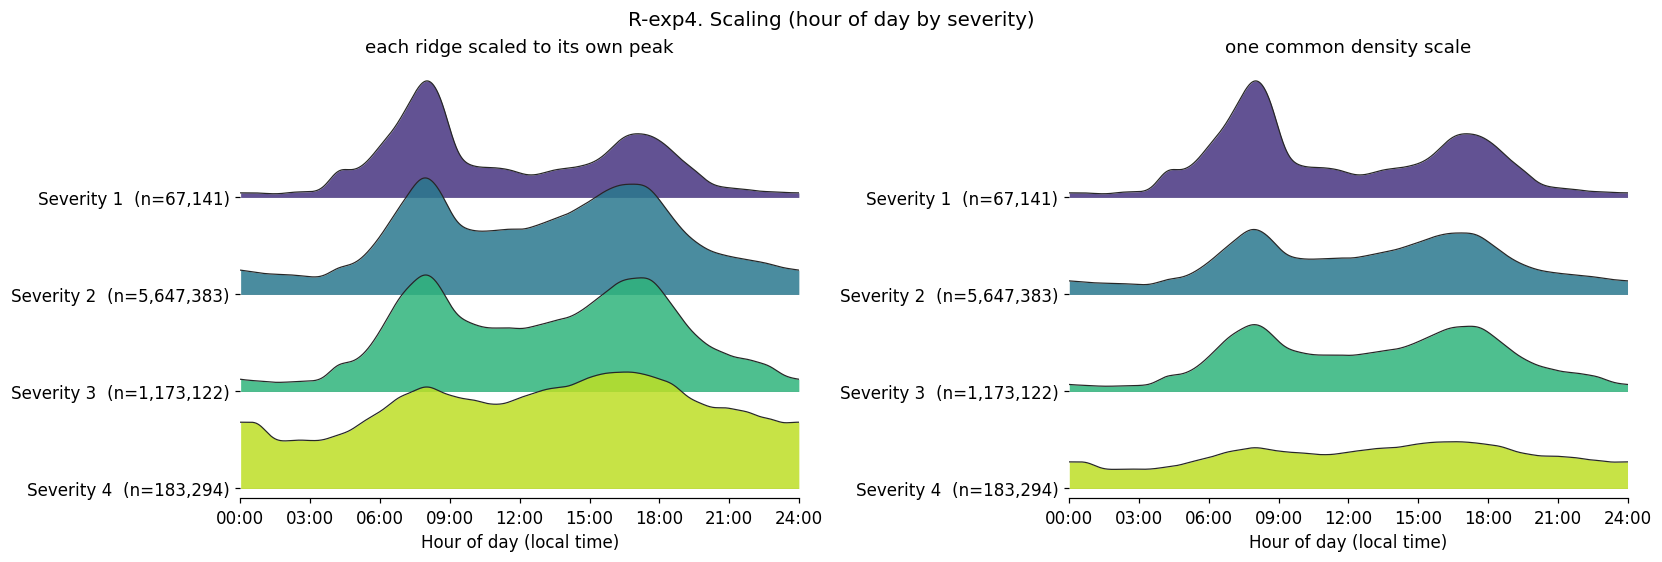

,n,mean,median,std,IQR
Severity 1,67141.0,11.57,10.02,5.11,8.93
Severity 2,5647383.0,12.78,13.27,5.50,8.90
Severity 3,1173122.0,12.96,13.38,5.22,8.83
Severity 4,183294.0,12.78,13.30,6.32,10.02


In [24]:
ridge_compare(g_sev, [dict(scaling="independent", title="each ridge scaled to its own peak"),
                      dict(scaling="shared", title="one common density scale")],
              figsize=(15, 5), suptitle="R-exp4. Scaling (hour of day by severity)", fname="fig_r4_scaling",
              bw=0.4, overlap=1.2, order=list(g_sev), **HOUR)
display(group_stats(g_sev))

### Final ridgeline plots
Bandwidth 0.4 h for hour of day; ridges scaled to their own peak unless stated.

In [25]:
RFINAL = dict(bw=0.4, overlap=1.5)  

**Ridgeline A:** hour of day by weekday.

saved images/fig_ridge_A_hour_by_weekday.png


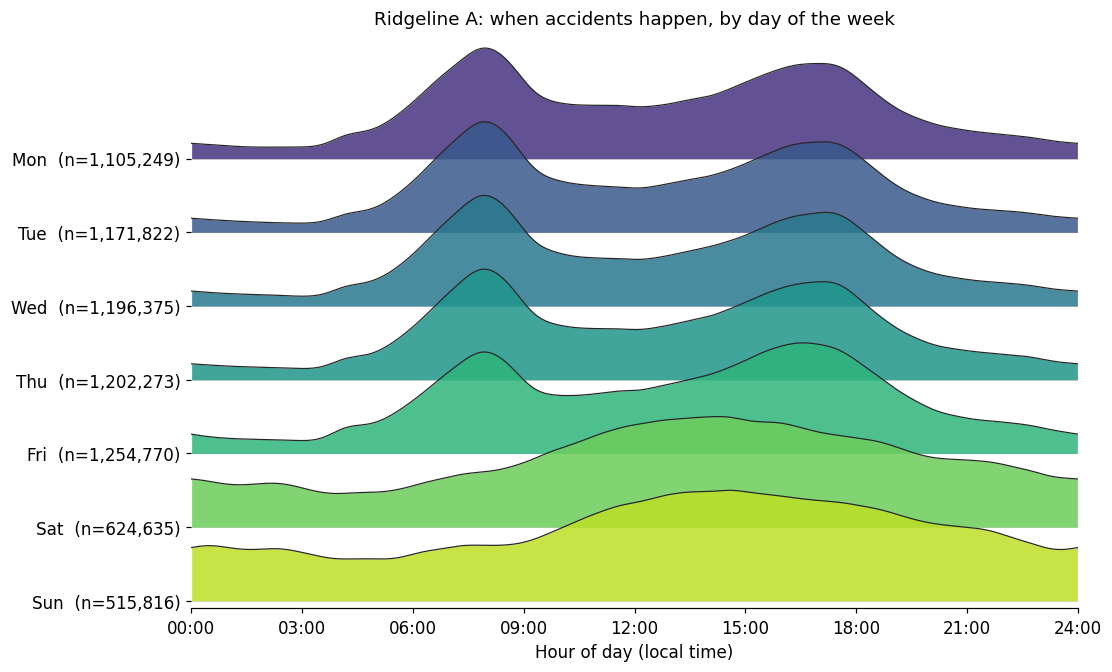

In [26]:
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
ridgeline(ax, g_dow, order=DOW_NAMES, title="Ridgeline A: when accidents happen, by day of the week", **RFINAL, **HOUR)
save(fig, "fig_ridge_A_hour_by_weekday")

**Ridgeline B:** day-of-year density, one ridge per year (shared scale).

saved images/fig_ridge_B_season_by_year.png


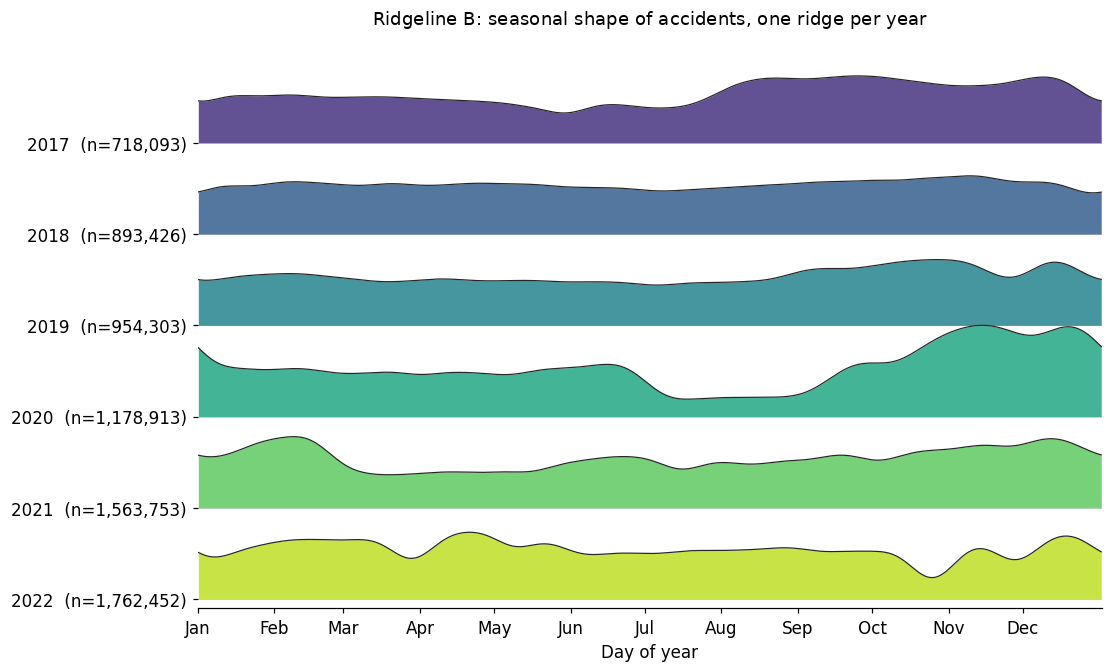

In [27]:
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
ridgeline(ax, g_year, lo=0, hi=366, bw=8, nbins=732, circular=True, overlap=1.0, scaling="shared", order=sorted(g_year),
          xlabel="Day of year", xticks=MONTH_TICKS, title="Ridgeline B: seasonal shape of accidents, one ridge per year")
save(fig, "fig_ridge_B_season_by_year")

**Ridgeline C:** visibility and wind speed by severity (median = bar, mean = diamond).

saved images/fig_ridge_C_visibility_wind_by_severity.png


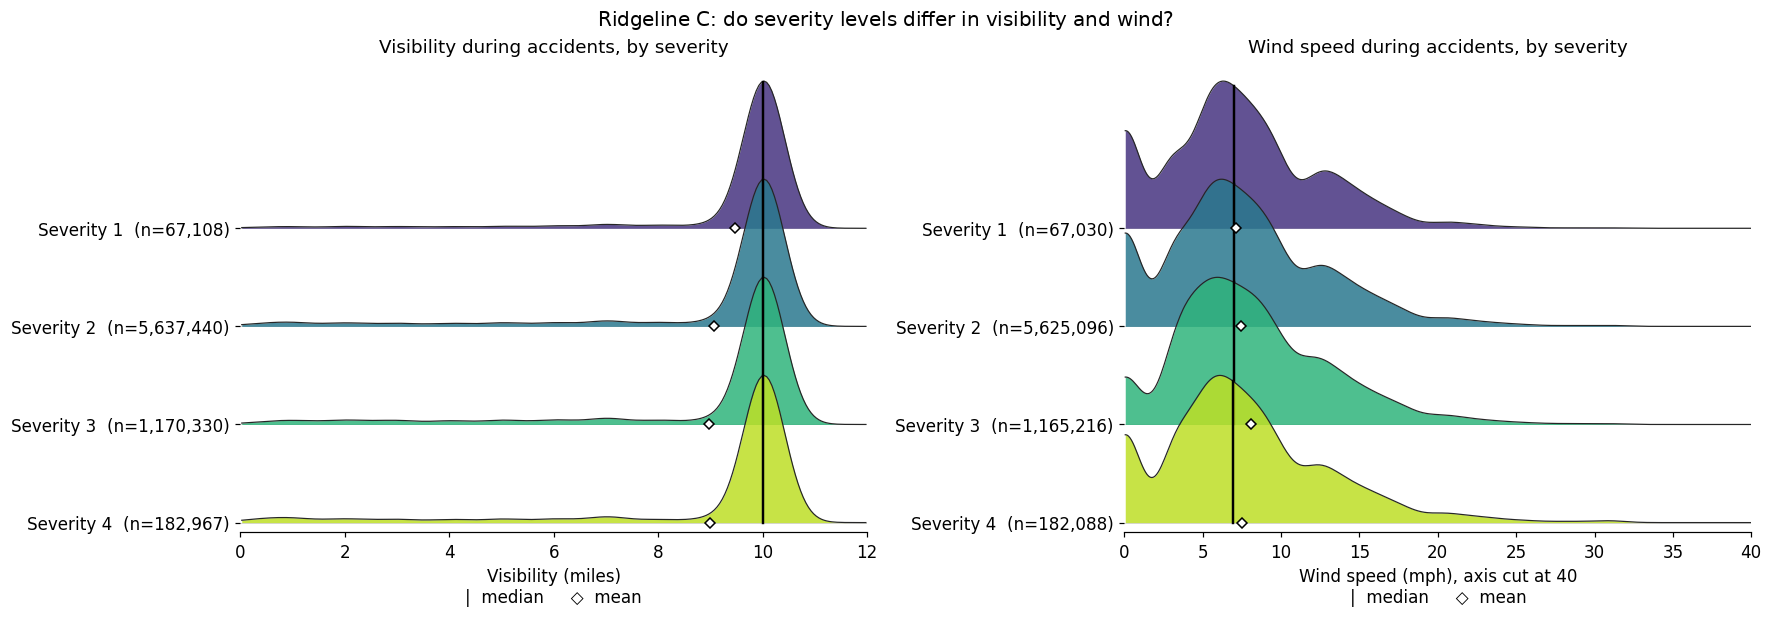

,n,mean,median,std,IQR
Severity 1,67108.0,9.46,10.0,1.78,0.0
Severity 2,5637440.0,9.06,10.0,2.35,0.0
Severity 3,1170330.0,8.97,10.0,2.44,0.0
Severity 4,182967.0,9.00,10.0,2.51,0.0


,n,mean,median,std,IQR
Severity 1,67030.0,7.13,7.0,5.03,7.0
Severity 2,5625096.0,7.44,7.0,5.23,6.5
Severity 3,1165216.0,8.10,7.0,4.96,5.8
Severity 4,182088.0,7.52,6.9,5.36,6.5


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), constrained_layout=True)
ridgeline(axes[0], g_vis, lo=0, hi=12, bw=0.4, nbins=240, order=list(g_vis), overlap=1.5, markers=True,
          xlabel="Visibility (miles)", title="Visibility during accidents, by severity")
ridgeline(axes[1], g_wind, lo=0, hi=40, bw=1.0, nbins=400, order=list(g_wind), overlap=1.5, markers=True,
          xlabel="Wind speed (mph), axis cut at 40", title="Wind speed during accidents, by severity")
fig.suptitle("Ridgeline C: do severity levels differ in visibility and wind?", fontsize=13)
save(fig, "fig_ridge_C_visibility_wind_by_severity")
display(group_stats(g_vis)); display(group_stats(g_wind))

## 6. Summary numbers used in the report
Caution: monthly shares in this cell (e.g. peak month) are computed on raw counts and are affected by growth within the year and by the source changes noted above.

In [30]:
lines = []
def add(title, obj):
    s = obj.to_string() if hasattr(obj, "to_string") else str(obj)
    print(f"\n=== {title} ===\n{s}")
    lines.append(f"\n=== {title} ===\n{s}")

yearly = dfr.groupby("year").size()
add("accidents per year", pd.DataFrame({"count": yearly, "pct_change": yearly.pct_change().mul(100).round(1)}))

season = (dfr[dfr["state"].isin(top_states)].groupby(["state", "month"]).size().unstack(fill_value=0)
          .reindex(columns=range(1, 13), fill_value=0).loc[top_states])
share = season.div(season.sum(axis=1), axis=0)
add("peak month per top state (1 = January)", pd.DataFrame({
    "peak_month": season.idxmax(axis=1), "peak_month_share_%": (share.max(axis=1) * 100).round(1),
    "Nov-Feb_share_%": (share[[11, 12, 1, 2]].sum(axis=1) * 100).round(1)}))

full_days = pd.date_range(RANGE_START, RANGE_END, freq="D")
daily = dfr.groupby("date").size().reindex(full_days, fill_value=0)
wk = daily.groupby(daily.index.dayofweek >= 5).mean().rename({False: "weekday", True: "weekend"})
add("mean accidents per day", wk.round(1))

# CAUTION: argmax is restricted to a window, so a window with no true peak returns its boundary
# (e.g. the weekend 'morning peak' = 11.99 h is just the window edge, not a real peak).
def peaks(frame):
    x, d = kde_binned(frame["hour_f"].values, 0, 24, 0.5, 1440, circular=True)
    am, pm = (x >= 5) & (x < 12), (x >= 12) & (x < 22)
    def peak(mask):                                       # interior maximum only; a window-edge maximum is not a peak
        k = np.argmax(d[mask]); return round(float(x[mask][k]), 2) if 0 < k < mask.sum() - 1 else float("nan")
    return {"morning_peak_h": peak(am), "afternoon_peak_h": peak(pm)}
add("peak hours (weekday vs weekend)", pd.DataFrame({"weekday": peaks(dfr[dfr.dow < 5]), "weekend": peaks(dfr[dfr.dow >= 5])}))

add("severity mix (%)", dfr["severity"].value_counts(normalize=True).sort_index().mul(100).round(1))
add("share of severity 3-4 by hour block (%)",
    dfr.assign(block=pd.cut(dfr["hour_f"], [0, 6, 12, 18, 24], right=False, labels=["00-06", "06-12", "12-18", "18-24"]))
       .groupby("block")["severity"].apply(lambda s: (s >= 3).mean() * 100).round(1))
if "weather_group" in dfr:
    add("accidents per weather group", dfr["weather_group"].value_counts())
    if "temp" in dfr:
        add("median temperature (°F) per weather group", dfr.groupby("weather_group")["temp"].median().round(1))
if "wind" in dfr:
    add("wind speed (mph) per severity: median / 90th percentile",
        dfr.groupby("severity")["wind"].quantile([0.5, 0.9]).unstack().round(1).rename(columns={0.5: "median", 0.9: "p90"}))
add("mean severity per year (top states)", dfr[dfr["state"].isin(top_states)].groupby(["year"])["severity"].mean().round(3))
with open(f"{IMG_DIR}/inference_numbers.txt", "w") as f:
    f.write("\n".join(lines))
print("\nsaved", f"{IMG_DIR}/inference_numbers.txt")


=== accidents per year ===
        count  pct_change
year                     
2017   718093         NaN
2018   893426        24.4
2019   954303         6.8
2020  1178913        23.5
2021  1563753        32.6
2022  1762452        12.7

=== peak month per top state (1 = January) ===
       peak_month  peak_month_share_%  Nov-Feb_share_%
state                                                 
CA             12                11.3             38.4
FL             12                11.6             39.1
TX             12                 9.9             36.5
SC             12                10.8             36.4
NC             12                10.4             36.2
NY              9                 9.5             32.7
VA             12                12.1             37.3
PA             12                11.8             39.8
MN             12                18.1             50.9
OR             12                14.6             45.9

=== mean accidents per day ===
weekday    3789.4
weeken